In [1]:
import pandas as pd
import os
import re
import matplotlib
import numpy as np
import json
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.colors as mcolors
import matplotlib.cm as cm

In [2]:
plt.rcParams['axes.labelsize'] = 18
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15
plt.rcParams['figure.autolayout'] = True
matplotlib.rcParams['font.family'] = 'serif'

Temperature Profiles of PFR

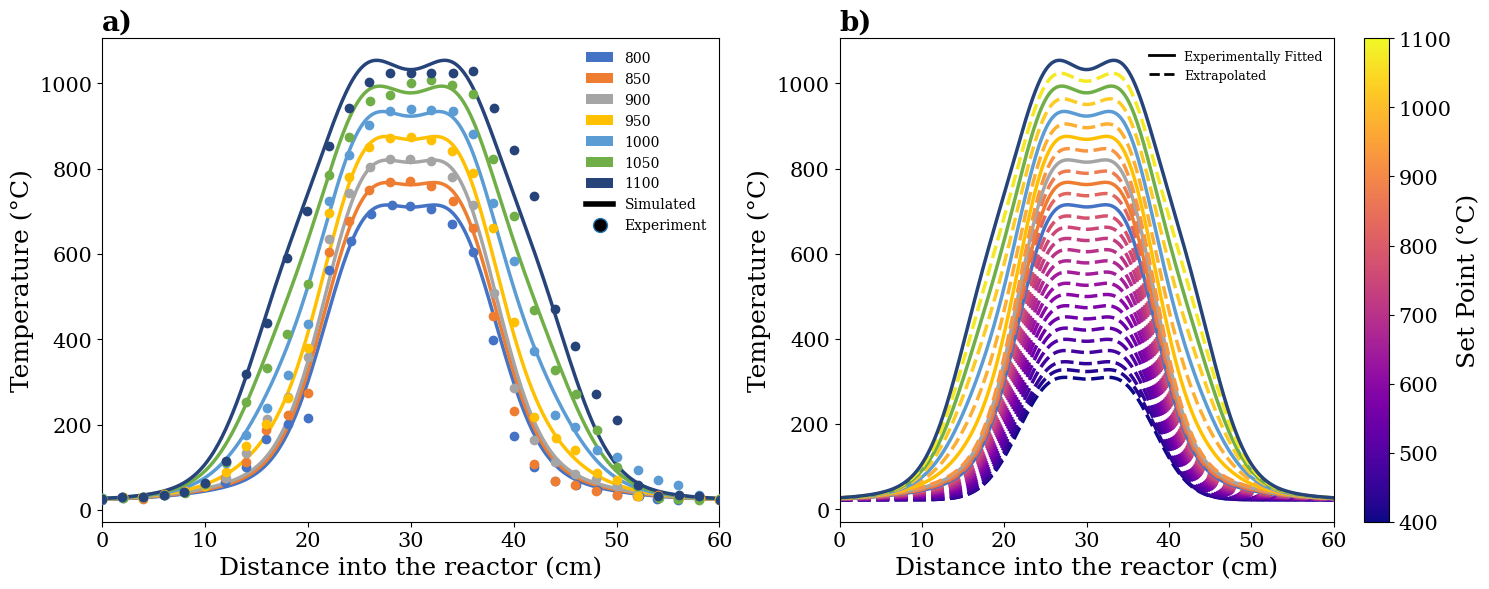

In [67]:
#  --- Temperature profiles: imposed vs simulated ---
# results = results_for_all_chemkins[cn]

def color_for_temperature(value, min_temp=400, max_temp=1100):
    color_map = plt.get_cmap('plasma')
    clipped_value = np.clip(value, min_temp, max_temp)
    normalized = (clipped_value - min_temp) / (max_temp - min_temp)
    return color_map(normalized)

def plot_experiment_temperature_profiles(temp): 
    temperature_profiles = pd.read_csv('/projects/westgroup/nora/Code/projects/rebasing_PFAS/models/PFAS/insights_from_Weber/PFOA+Air/temperature_profiles_from_literature.csv')
    index_of_x = temperature_profiles.columns.get_loc(str(temp))
    index_of_y = index_of_x+1 
    
    distances_str = temperature_profiles.iloc[:, index_of_x]
    distances = [float(x) for x in distances_str[1:]]
    
    temperatures_at_distances_str = temperature_profiles.iloc[:, index_of_y]
    temperatures_at_distances = [float(x) for x in temperatures_at_distances_str[1:]]
            
    return distances, temperatures_at_distances

rbg_colors = {800: (68, 114, 196), 
              850: (238, 125, 49), 
              900: (165, 165, 165), 
              950: (255, 192, 2), 
              1000: (91, 156, 213), 
              1050: (112, 174, 71), 
              1100: (38, 68, 121)}


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
length = 0.6
x_fine = np.linspace(0, length, 500)

with open('analytical_temperature_profiles.json', 'r') as file:
   T_analytical_data = json.load(file)



nominal_temperatures = [800, 850, 900, 950, 1000, 1050, 1100]

with open('analytical_temperature_profiles.json', 'r') as file:
   T_analytical_data = json.load(file)



for nominal_T_C in nominal_temperatures:


    
    # try:
    non_plasma_color = tuple([color_num/255 for color_num in rbg_colors[nominal_T_C]])
    color=non_plasma_color
        
        #plot the temperature profiles from experiment
        # exp_distance, exp_temps = plot_experiment_temperature_profiles(str(nominal_T_C))
        # ax1.plot(exp_distance, exp_temps, 'o', color=color)
    # except KeyError: 
    #     color = color_for_temperature(nominal_T_C)

    # Analytical profile
    # T_analytical = np.array([T_profile_K(x, nominal_T_C) for x in x_fine]) - 273.15
    ax1.plot(x_fine * 100, T_analytical_data[str(nominal_T_C)], '-', color=color, linewidth=2.5) #alpha=0.5)


    #plot the temperature profiles from experiment
    exp_distance, exp_temps = plot_experiment_temperature_profiles(str(nominal_T_C))
    ax1.plot(exp_distance, exp_temps, 'o', color=color, zorder=10)
    
    # Simulated
    # results = results_T = results_for_all_chemkins[cn]
    # r = results[nominal_T_C]
    # ax1.plot(r['x'] * 100, r['T'] - 273.15, '--', color=color, linewidth=1.5, label=f'{nominal_T_C} °C')  


# make a custom label
custom_lines = []
T_names = []

for T, col in rbg_colors.items(): 
    non_plasma_color = tuple([color_num/255 for color_num in col])
    custom_lines.append(Patch(facecolor=non_plasma_color, label=T))
    T_names.append(T)

custom_lines.append(Line2D([0], [0], color='black', linestyle='-', lw=4, label='Simulated'))
custom_lines.append(Line2D([0], [0], marker='o', markerfacecolor='black', markersize=10, linestyle='', lw=4, label='Experiment'))


model_names = T_names + ['Simulated', 'Experiment']



ax1.legend(custom_lines, model_names, loc='upper right', fontsize=10, frameon=False)       
    
    
ax1.set_xlabel('Distance into the reactor (cm)')
ax1.set_ylabel('Temperature (°C)')
#ax1.set_title('Temperature profiles of simulated PFR', fontsize=16)
ax1.set_title('a)', fontsize=20, fontweight='bold', loc='left')

# ax1.legend()
ax1.set_xlim(0, 60)


nominal_temperatures = np.arange(400, 1101, 25)

T_colors_second_plot = []
T_names_second_plot = []
for nominal_T_C in nominal_temperatures:


    
    try:
        non_plasma_color = tuple([color_num/255 for color_num in rbg_colors[nominal_T_C]])
        color=non_plasma_color
        ls = '-'
        
        #plot the temperature profiles from experiment
        # exp_distance, exp_temps = plot_experiment_temperature_profiles(str(nominal_T_C))
        # ax1.plot(exp_distance, exp_temps, 'o', color=color)
    except KeyError: 
        color = color_for_temperature(nominal_T_C)
        ls = '--'

    # Analytical profile
    # T_analytical = np.array([T_profile_K(x, nominal_T_C) for x in x_fine]) - 273.15
    ax2.plot(x_fine * 100, T_analytical_data[str(nominal_T_C)], ls, color=color, linewidth=2.5) #alpha=0.5)
    # T_colors_second_plot.append(Line2D([0], [0], color=color, linestyle=ls, lw=2, label=nominal_T_C))
    # T_names_second_plot.append(nominal_T_C)

#custom second legend
T_colors_second_plot = [Line2D([0], [0], color='black', linestyle='-', lw=2, label='Fit to experiments'),
                        Line2D([0], [0], color='black', linestyle='--', lw=2, label='Extrapolated')]
T_names_second_plot = ['Experimentally Fitted', 'Extrapolated']

ax2.legend(T_colors_second_plot, T_names_second_plot, loc='upper right', fontsize=9, frameon=False)      


# Create a ScalarMappable using the same parameters as your function
norm = mcolors.Normalize(vmin=400, vmax=1100)
sm = cm.ScalarMappable(cmap='plasma', norm=norm)
sm.set_array([])

# Add the colorbar
cbar = fig.colorbar(sm, ax=ax2)
cbar.set_label('Set Point (°C)')

    
ax2.set_xlabel('Distance into the reactor (cm)')
ax2.set_ylabel('Temperature (°C)')
#ax1.set_title('Temperature profiles of simulated PFR', fontsize=16)
ax2.set_title('b)', fontsize=20, fontweight='bold', loc='left')

# ax1.legend()
ax2.set_xlim(0, 60)

    #plot the temperature profiles from experiment
    # exp_distance, exp_temps = plot_experiment_temperature_profiles(str(nominal_T_C))
    # ax1.plot(exp_distance, exp_temps, 'o', color=color, zorder=10)
    
    # Simulated
    # results = results_T = results_for_all_chemkins[cn]
    # r = results[nominal_T_C]
    # ax1.plot(r['x'] * 100, r['T'] - 273.15, '--', color=color, linewidth=1.5, label=f'{nominal_T_C} °C')  

fig.savefig('temperature_profile_results.png')

PFR simulations results (Weber, RMG main, RMG PFAS) 

In [3]:
error_data=pd.read_csv(f'/projects/westgroup/nora/Code/projects/rebasing_PFAS/models/PFAS/insights_from_Weber/PFOA+Air/literature_data/50mlpermin/CF4_lowerbound_errors.csv', header=None)
        

In [4]:
def get_experiment_data(exp_label):
        
    spec_data=pd.read_csv(f'/projects/westgroup/nora/Code/projects/rebasing_PFAS/models/PFAS/insights_from_Weber/PFOA+Air/literature_data/{exp_label}.csv')
        
    exp_data = {}
    for header in ['model', 'experiments', 'error']:
        index_of_x = spec_data.columns.get_loc(header)
        index_of_y = index_of_x+1 

        x_values_raw = spec_data.iloc[:, index_of_x]
        x_values = [float(x) for x in x_values_raw[1:]] #removes first header of 'X' or 'Y'
    
        y_values_raw = spec_data.iloc[:, index_of_y]
        y_values = [float(x) for x in y_values_raw[1:]]
        
        exp_data[header]=(x_values, y_values)
        
        
    return exp_data


def get_errors_50mlpermin():

    species_to_get_error_data_for = ['HF', 'C2F4', 'CO2', 'C2F6', 'CO', 'CF4', 'COF2'] 
    error_data_dict = {}
    for species in species_to_get_error_data_for: 
        error_data=pd.read_csv(f'/projects/westgroup/nora/Code/projects/rebasing_PFAS/models/PFAS/insights_from_Weber/PFOA+Air/literature_data/50mlpermin/{species}_lowerbound_errors.csv', header=None)
        
        lowerbound_error = error_data.iloc[:,1]
        lowerbound_error_temp = error_data.iloc[:,0]
        error_data_dict[species]=(lowerbound_error, lowerbound_error_temp)
    return error_data_dict


def get_raw_data_50mLmin(spec): #this is for a plot in the SI 
    """retrieve the raw data, given via an excel sheet from Weber. Initial concentrations in excel sheet: PFOA 467 ppm, H2O 750 ppm"""
    init_PFOA = 467 #ppm 
    
    approx_temp = [390, 410, 440, 510, 540, 570, 615, 660, 710, 765, 800, 835, 875, 910, 975, 1000] #double checked
    
    HF_conc = [0, 0, 10, 233, 280, 450, 617, 864, 1027, 1274, 1459, 1525, 1623, 1658, 1666, 1721] #double checked
    COF2_conc = [0, 0, 0, 0, 31, 132, 173, 214, 226, 409, 620, 647, 722, 711, 709, 710] #double checked
    CO2_conc = [1, 8, 31, 75, 161, 254, 276, 336, 502, 1249, 1499, 1578, 1627, 1602, 1522, 1515] #double checked
    CO_conc = [0, 5, 31, 27, 48, 211, 283, 378, 435, 502, 517, 712, 798, 830, 830, 848]
    C2F6_conc = [0, 0, 0, 4, 6, 7, 16, 62, 88, 138, 208, 313, 286, 242, 211, 126]
    C2F4_conc = [0, 0, 0, 0, 0, 0, 4, 15, 31, 73, 61, 42, 21, 16, 0, 0]
    CF4_conc = [0, 0, 0, 3, 2, 2, 2, 2, 2, 3, 48, 156, 201, 242, 248, 279]
    
    conc_ratio_dict = {'HF' : np.array(HF_conc)/init_PFOA, 
    'COF2' : np.array(COF2_conc)/init_PFOA, 
    'CO2' : np.array(CO2_conc) / init_PFOA, 
    'CO' : np.array(CO_conc) / init_PFOA, 
    'C2F6' : np.array(C2F6_conc) / init_PFOA, 
    'C2F4' : np.array(C2F4_conc) / init_PFOA, 
    'CF4' : np.array(CF4_conc) / init_PFOA}
    
    return (approx_temp, conc_ratio_dict[spec])

def get_raw_data_150mLmin(spec): 
    """retrieve the raw data, given via an excel sheet from Weber. Inital concentrations in excel sheet: PFOA 402 ppm.  """
    init_PFOA = 402
    
    exp_temp = [400, 425, 450, 500, 550, 575, 630, 660, 690, 720, 765, 800, 835, 875, 910, 975, 1000] #experimental measurements do not include 475
    
    HF_conc = [0, 0, 3.02, 49.47, 149.8, 221.17, 290.88, 467.82, 762.73, 1433, 1671, 1756, 1868, 1888, 1910, 1922, 1931] #double checked
    COF2_conc = [0, 0, 0, 0, 0, 0, 7.28, 11.44, 15.13, 17.21, 32.82, 188.28, 333.53, 565.88, 667.69, 677.92, 680.17] #double checked
    CO2_conc = [0, 0, 1.09, 24.82, 47.31, 61.37, 142, 301, 416, 569, 612.45, 706.13, 804.46, 815, 822, 827, 838] #double checked
    CO_conc = [0, 0, 0, 6.12, 9.82, 11.27, 19.89, 62.25, 202.36, 301.08, 410, 486, 580, 610, 640, 670, 690] #double checked
    C2F6_conc = [0, 0, 0, 0, 0, 0, 8.7, 11.5, 15.3, 21.2, 98.23, 226, 268.87, 301, 322, 366, 371] #double checked
    C2F4_conc = [0, 0, 0, 0, 0, 0, 1.76, 13.36, 36.59, 60.28, 58.33, 10.36, 0, 0, 0, 0, 0] #double checked 
    CF4_conc = [0, 0, 0, 0, 0, 0, 1.2, 1.59, 2.43, 2.94, 4.69, 11.07, 26.27, 52.85, 78.85, 100, 110] #double checked
    
    conc_ratio_dict = {'HF' : np.array(HF_conc)/init_PFOA, 
    'COF2' : np.array(COF2_conc)/init_PFOA, 
    'CO2' : np.array(CO2_conc) / init_PFOA, 
    'CO' : np.array(CO_conc) / init_PFOA, 
    'C2F6' : np.array(C2F6_conc) / init_PFOA, 
    'C2F4' : np.array(C2F4_conc) / init_PFOA, 
    'CF4' : np.array(CF4_conc) / init_PFOA}
    
    return (exp_temp, conc_ratio_dict[spec])

# 150 ml/min plots

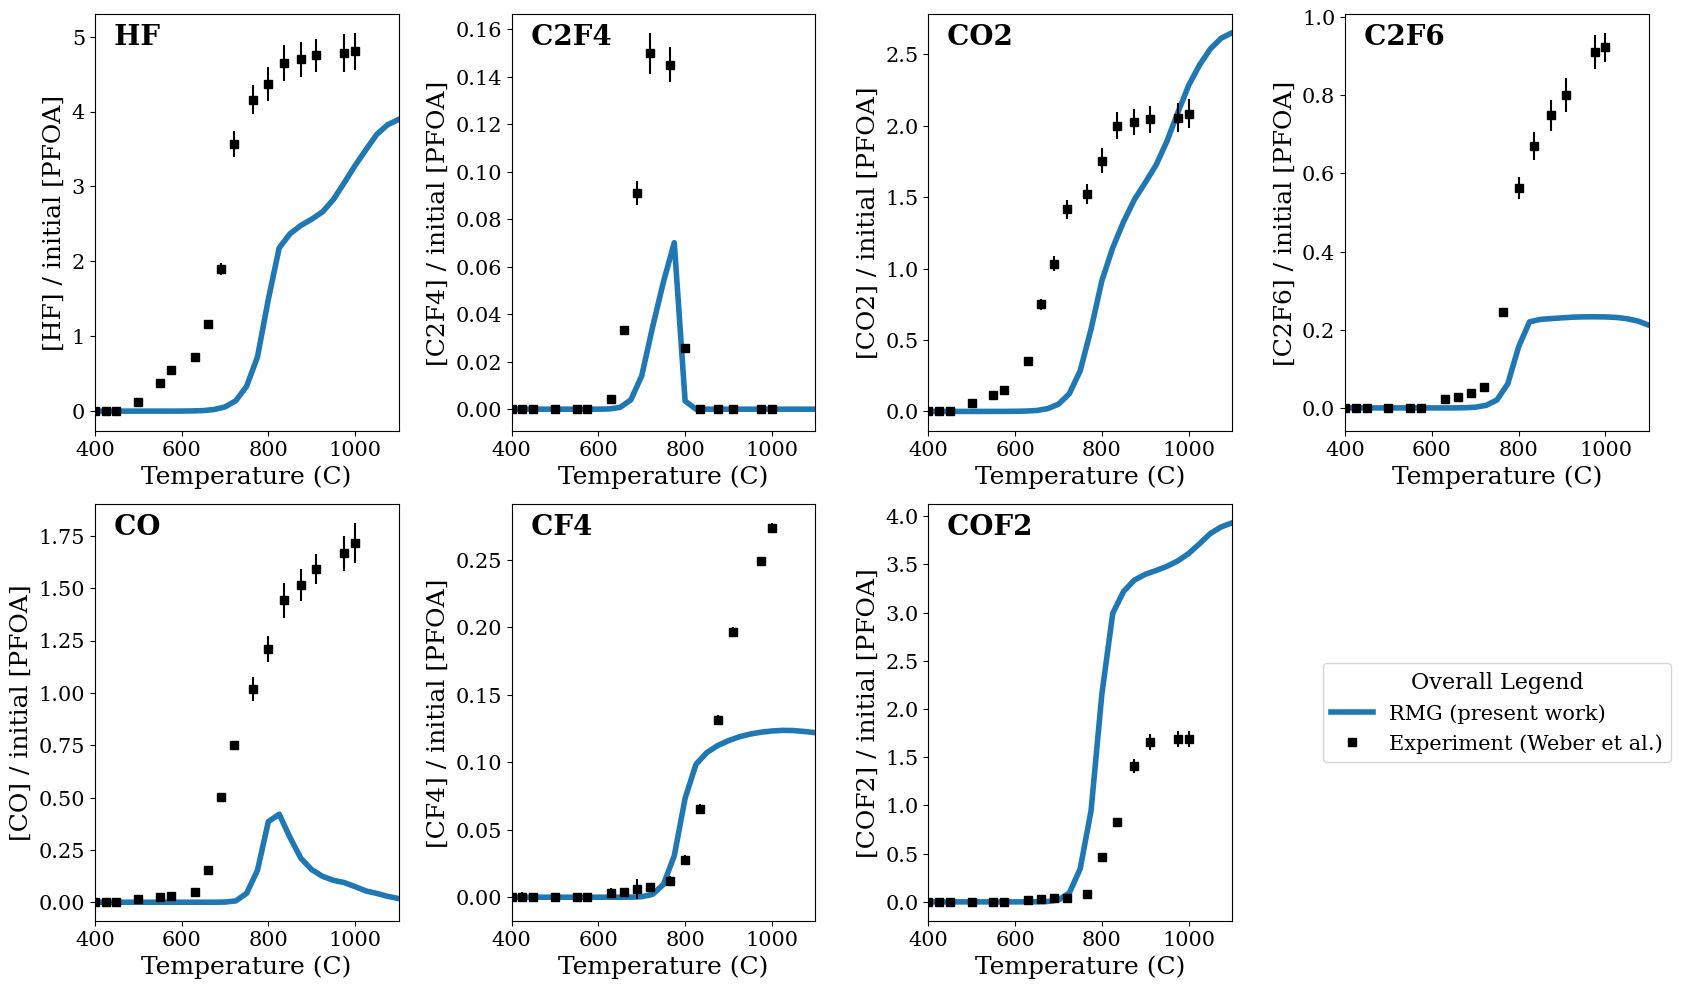

In [6]:
with open('./weber_results.json', 'r') as file:
   weber_results_data = json.load(file)


with open('./rmg_skel_AB2_150ml_324corespec.json', 'r') as file:
   rmg_pfas_results_data = json.load(file)

with open('./rmg_main_results.json', 'r') as file:
   rmg_main_results_435spec_data = json.load(file)

with open('./rmg_main_300spec_results.json', 'r') as file:
   rmg_main_results_300spec_data = json.load(file)


plot_concentration_ratios_weber = ['HF', 'C2F4', 'CO2', 'C2F6', 'CO', 'CF4', 'COF2'] #species names in Weber model


axes_for_plotting_weber = {'HF': [0,0],
                    'C2F4': [0,1],
                    'CO2': [0,2],
                    'C2F6': [0,3],
                    'CO': [1,0],
                    'CF4': [1,1],
                    'COF2': [1,2]}

plot_concentration_ratios = ['HF(11)', 'C2F4(64)', 'CO2(13)', 'C2F6(51)', 'CO(12)', 'CF4(23)', 'COF2(25)']

axes_for_plotting = {'HF(11)': [0,0],
                    'C2F4(64)': [0,1],
                    'CO2(13)': [0,2],
                    'C2F6(51)': [0,3],
                    'CO(12)': [1,0],
                    'CF4(23)': [1,1],
                    'COF2(25)': [1,2]}

exp_mapping = {'HF(11)': 'HF', 
'C2F4(64)':'C2F4', 
'CO2(13)':'CO2', 
'C2F6(51)':'C2F6', 
'CO(12)':'CO', 
'CF4(23)': 'CF4', 
'COF2(25)':'COF2'}

fig, axs = plt.subplots(2, 4, figsize=(17, 10))
chemkins_to_convert=['317_edited']
chemkins_to_convert=[317, '317_edited']

lw = 4

for RMG_spc, web_spc in zip(plot_concentration_ratios, plot_concentration_ratios_weber): 
    
    # print(RMG_spc)

    #get plotting axis
    plotting_axis = axes_for_plotting[RMG_spc]


    #RMG PFAS
    exit_concentrations,  temps_to_plot = rmg_pfas_results_data[RMG_spc]
    axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations, '-', linewidth = lw, color='tab:blue', label="RMG (present work)")


    #RMG main
    exit_concentrations,  temps_to_plot = rmg_main_results_300spec_data[RMG_spc]
    # axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations, '-.', linewidth=lw, color='tab:blue', label="RMG (main)")

   
    #RMG main
    exit_concentrations,  temps_to_plot = rmg_main_results_435spec_data[RMG_spc]
    # axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations, '--', linewidth=lw, color='tab:blue', label="RMG (main)")

   



    #Weber mech using our simulation
    (exit_concentrations_weber, temps_to_plot) = weber_results_data[web_spc]
    # axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations_weber, ':', color='r', linewidth = lw, label = 'Weber et al.')

    
    #grab Weber experiment data that I pulled from his published plots via data digitilizer
    exp_data = get_experiment_data(exp_mapping[RMG_spc])

    #error bars
    #make sure their ordered 
    errors = sorted([(x, y) for x, y in zip(exp_data['error'][0], exp_data['error'][1])]) #By default, when sorting a list of tuples, sorted() will sort based on the first element of each tuple
    experiments = sorted([(x, y) for x, y in zip(exp_data['experiments'][0], exp_data['experiments'][1])])

    yerrs = []
    for (exp_x, exp_y), (raw_error_x, raw_error_y) in zip(experiments, errors):
        if raw_error_y == 1.0232558139534884:
            raw_error_y = 0.96 #modifying this last error bar on C2F6 because it looks like there was a mistake (the error bar is way too long)
        error_length = raw_error_y - exp_y
        # print(error_length)
        yerrs.append(abs(error_length))
        # axs[plotting_axis[0], plotting_axis[1]].errorbar(exp_x, exp_y, yerr = abs(error_length), fmt='none', c='black')

    # axs[plotting_axis[0], plotting_axis[1]].plot(exp_data['experiments'][0], exp_data['experiments'][1], 's', c='black', label='Weber exp (data digitilizer)')

    #also grab the Weber experiment data that I directly received via emailed excel sheet, just to be safe
    exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet = get_raw_data_150mLmin(exp_mapping[RMG_spc])
    for temp, conc_ratio, yerr in zip(exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet, yerrs):
        axs[plotting_axis[0], plotting_axis[1]].errorbar(temp, conc_ratio, yerr = yerr, fmt='none', c='black')
        axs[plotting_axis[0], plotting_axis[1]].plot(temp, conc_ratio, 's', c='black') 
   
        # axs[plotting_axis[0], plotting_axis[1]].errorbar(exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet, yerr = yerrs, fmt='none', c='black')
        # axs[plotting_axis[0], plotting_axis[1]].plot(exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet, 's', c='black', label = 'Weber (excel sheet)') 
   
    axs[plotting_axis[0], plotting_axis[1]].plot([],[], 's', c='black', label = 'Experiment (Weber et al.)') 


    axs[plotting_axis[0], plotting_axis[1]].set_xlabel('Temperature (C)')
    axs[plotting_axis[0], plotting_axis[1]].set_ylabel(f'[{web_spc}] / initial [PFOA]')
    axs[plotting_axis[0], plotting_axis[1]].set_title(f'  {web_spc}', fontsize = 20, fontweight='bold', loc='left', y=1.0, pad=-22)
    axs[plotting_axis[0], plotting_axis[1]].set_xlim(400, 1100)
    # axs[plotting_axis[0], plotting_axis[1]].set_ylim(0, 2)


#custom legend that will sit in empty plot
h, l = axs[plotting_axis[0], plotting_axis[1]].get_legend_handles_labels()


# target the empty subplot (bottom-right)
ax_legend = axs[1, 3]

# hide its axes and frame
ax_legend.axis('off')
ax_legend.set_frame_on(False)

# place the combined legend in this specific subplot
ax_legend.legend(h, l, loc='center', title="Overall Legend", fontsize=15, title_fontsize=16)

# plt.legend()
plt.show()
fig.savefig('./model_results_rmgpfas.pdf')

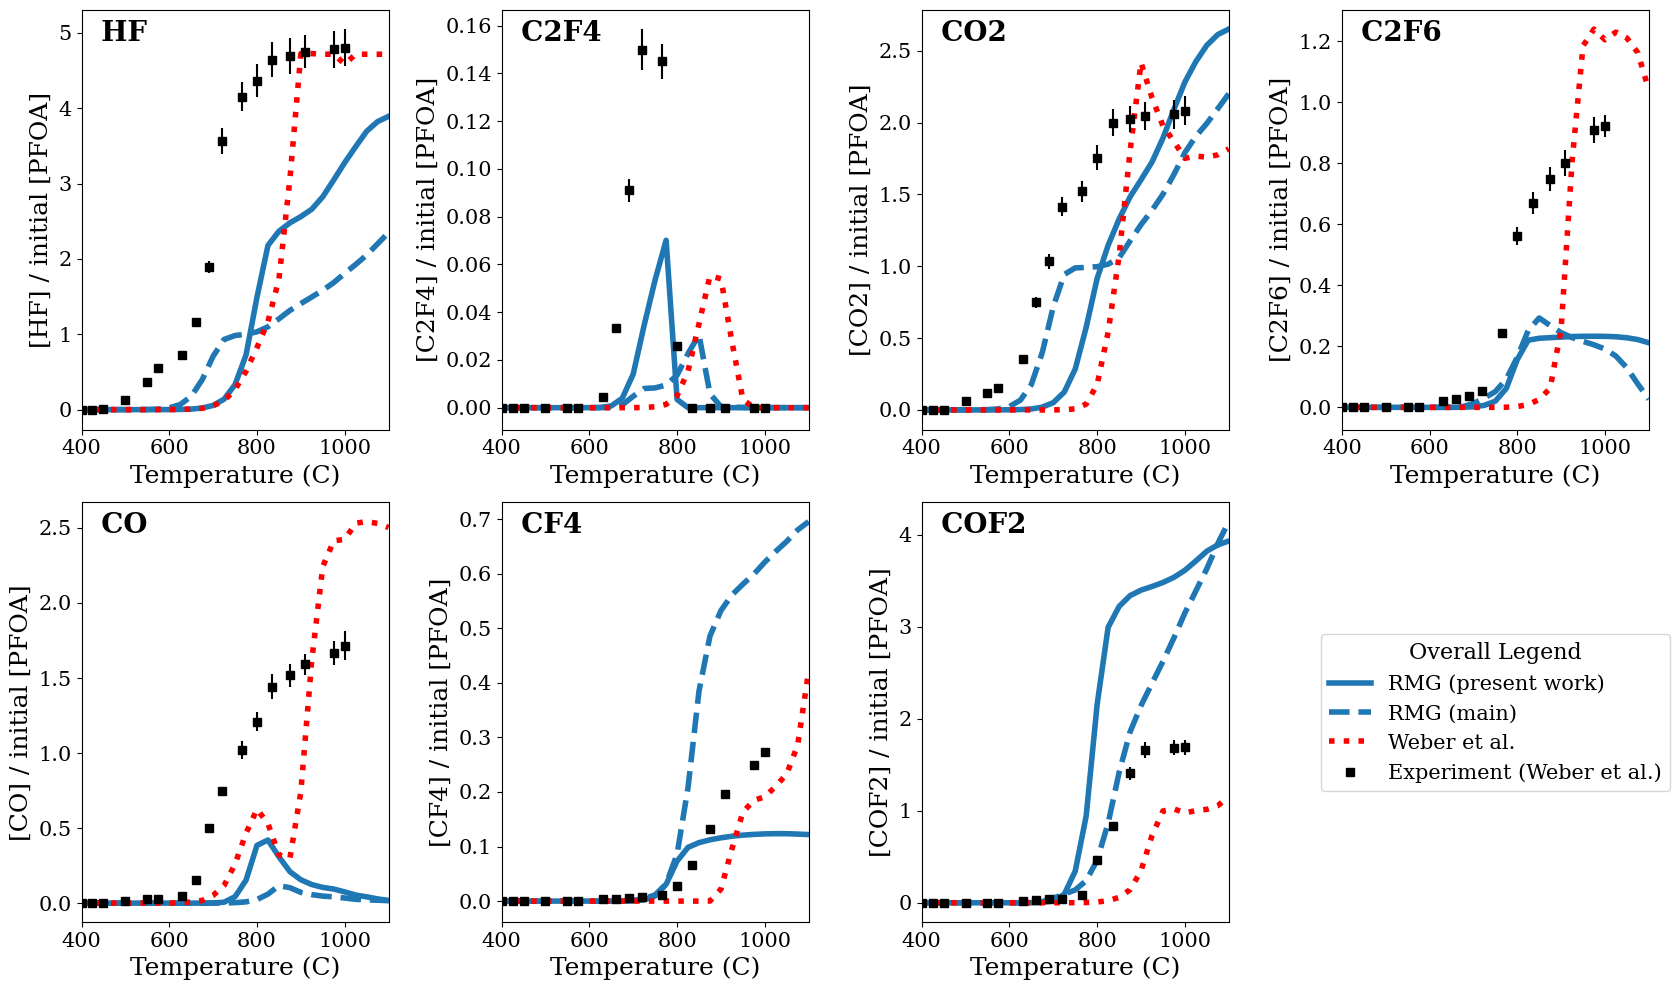

In [13]:
def get_experiment_data(exp_label):
        
    spec_data=pd.read_csv(f'/projects/westgroup/nora/Code/projects/rebasing_PFAS/models/PFAS/insights_from_Weber/PFOA+Air/literature_data/{exp_label}.csv')
        
    exp_data = {}
    for header in ['model', 'experiments', 'error']:
        index_of_x = spec_data.columns.get_loc(header)
        index_of_y = index_of_x+1 

        x_values_raw = spec_data.iloc[:, index_of_x]
        x_values = [float(x) for x in x_values_raw[1:]] #removes first header of 'X' or 'Y'
    
        y_values_raw = spec_data.iloc[:, index_of_y]
        y_values = [float(x) for x in y_values_raw[1:]]
        
        exp_data[header]=(x_values, y_values)
        
        
    return exp_data


def get_raw_data_50mLmin(spec): #this is for a plot in the SI 
    """retrieve the raw data, given via an excel sheet from Weber. Initial concentrations in excel sheet: PFOA 467 ppm, H2O 750 ppm"""
    init_PFOA = 467 #ppm 
    
    approx_temp = [390, 410, 440, 510, 540, 570, 615, 660, 710, 765, 800, 835, 875, 910, 975, 1000] #double checked
    
    HF_conc = [0, 0, 10, 233, 280, 450, 617, 864, 1027, 1274, 1459, 1525, 1623, 1658, 1666, 1721] #double checked
    COF2_conc = [0, 0, 0, 0, 31, 132, 173, 214, 226, 409, 620, 647, 722, 711, 709, 710] #double checked
    CO2_conc = [1, 8, 31, 75, 161, 254, 276, 336, 502, 1249, 1499, 1578, 1627, 1602, 1522, 1515] #double checked
    CO_conc = [0, 5, 31, 27, 48, 211, 283, 378, 435, 502, 517, 712, 798, 830, 830, 848]
    C2F6_conc = [0, 0, 0, 4, 6, 7, 16, 62, 88, 138, 208, 313, 286, 242, 211, 126]
    C2F4_conc = [0, 0, 0, 0, 0, 0, 4, 15, 31, 73, 61, 42, 21, 16, 0, 0]
    CF4_conc = [0, 0, 0, 3, 2, 2, 2, 2, 2, 3, 48, 156, 201, 242, 248, 279]
    
    conc_ratio_dict = {'HF' : np.array(HF_conc)/init_PFOA, 
    'COF2' : np.array(COF2_conc)/init_PFOA, 
    'CO2' : np.array(CO2_conc) / init_PFOA, 
    'CO' : np.array(CO_conc) / init_PFOA, 
    'C2F6' : np.array(C2F6_conc) / init_PFOA, 
    'C2F4' : np.array(C2F4_conc) / init_PFOA, 
    'CF4' : np.array(CF4_conc) / init_PFOA}
    
    return (approx_temp, conc_ratio_dict[spec])

def get_raw_data_150mLmin(spec): 
    """retrieve the raw data, given via an excel sheet from Weber. Inital concentrations in excel sheet: PFOA 402 ppm.  """
    init_PFOA = 402
    
    exp_temp = [400, 425, 450, 500, 550, 575, 630, 660, 690, 720, 765, 800, 835, 875, 910, 975, 1000] #experimental measurements do not include 475
    
    HF_conc = [0, 0, 3.02, 49.47, 149.8, 221.17, 290.88, 467.82, 762.73, 1433, 1671, 1756, 1868, 1888, 1910, 1922, 1931] #double checked
    COF2_conc = [0, 0, 0, 0, 0, 0, 7.28, 11.44, 15.13, 17.21, 32.82, 188.28, 333.53, 565.88, 667.69, 677.92, 680.17] #double checked
    CO2_conc = [0, 0, 1.09, 24.82, 47.31, 61.37, 142, 301, 416, 569, 612.45, 706.13, 804.46, 815, 822, 827, 838] #double checked
    CO_conc = [0, 0, 0, 6.12, 9.82, 11.27, 19.89, 62.25, 202.36, 301.08, 410, 486, 580, 610, 640, 670, 690] #double checked
    C2F6_conc = [0, 0, 0, 0, 0, 0, 8.7, 11.5, 15.3, 21.2, 98.23, 226, 268.87, 301, 322, 366, 371] #double checked
    C2F4_conc = [0, 0, 0, 0, 0, 0, 1.76, 13.36, 36.59, 60.28, 58.33, 10.36, 0, 0, 0, 0, 0] #double checked 
    CF4_conc = [0, 0, 0, 0, 0, 0, 1.2, 1.59, 2.43, 2.94, 4.69, 11.07, 26.27, 52.85, 78.85, 100, 110] #double checked
    
    conc_ratio_dict = {'HF' : np.array(HF_conc)/init_PFOA, 
    'COF2' : np.array(COF2_conc)/init_PFOA, 
    'CO2' : np.array(CO2_conc) / init_PFOA, 
    'CO' : np.array(CO_conc) / init_PFOA, 
    'C2F6' : np.array(C2F6_conc) / init_PFOA, 
    'C2F4' : np.array(C2F4_conc) / init_PFOA, 
    'CF4' : np.array(CF4_conc) / init_PFOA}
    
    return (exp_temp, conc_ratio_dict[spec])





with open('./weber_results.json', 'r') as file:
   weber_results_data = json.load(file)


with open('./rmg_skel_AB2_150ml_324corespec.json', 'r') as file:
   rmg_pfas_results_data = json.load(file)

with open('./rmg_main_results.json', 'r') as file:
   rmg_main_results_435spec_data = json.load(file)

with open('./rmg_main_300spec_results.json', 'r') as file:
   rmg_main_results_300spec_data = json.load(file)


plot_concentration_ratios_weber = ['HF', 'C2F4', 'CO2', 'C2F6', 'CO', 'CF4', 'COF2'] #species names in Weber model


axes_for_plotting_weber = {'HF': [0,0],
                    'C2F4': [0,1],
                    'CO2': [0,2],
                    'C2F6': [0,3],
                    'CO': [1,0],
                    'CF4': [1,1],
                    'COF2': [1,2]}

plot_concentration_ratios = ['HF(11)', 'C2F4(64)', 'CO2(13)', 'C2F6(51)', 'CO(12)', 'CF4(23)', 'COF2(25)']

axes_for_plotting = {'HF(11)': [0,0],
                    'C2F4(64)': [0,1],
                    'CO2(13)': [0,2],
                    'C2F6(51)': [0,3],
                    'CO(12)': [1,0],
                    'CF4(23)': [1,1],
                    'COF2(25)': [1,2]}

exp_mapping = {'HF(11)': 'HF', 
'C2F4(64)':'C2F4', 
'CO2(13)':'CO2', 
'C2F6(51)':'C2F6', 
'CO(12)':'CO', 
'CF4(23)': 'CF4', 
'COF2(25)':'COF2'}

fig, axs = plt.subplots(2, 4, figsize=(17, 10))
chemkins_to_convert=['317_edited']
chemkins_to_convert=[317, '317_edited']

lw = 4

for RMG_spc, web_spc in zip(plot_concentration_ratios, plot_concentration_ratios_weber): 
    
    # print(RMG_spc)

    #get plotting axis
    plotting_axis = axes_for_plotting[RMG_spc]


    #RMG PFAS
    exit_concentrations,  temps_to_plot = rmg_pfas_results_data[RMG_spc]
    axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations, '-', linewidth = lw, color='tab:blue', label="RMG (present work)")


    #RMG main
    exit_concentrations,  temps_to_plot = rmg_main_results_300spec_data[RMG_spc]
    # axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations, '-.', linewidth=lw, color='tab:blue', label="RMG (main)")

   
    #RMG main
    exit_concentrations,  temps_to_plot = rmg_main_results_435spec_data[RMG_spc]
    axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations, '--', linewidth=lw, color='tab:blue', label="RMG (main)")

   



    #Weber mech using our simulation
    (exit_concentrations_weber, temps_to_plot) = weber_results_data[web_spc]
    axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations_weber, ':', color='r', linewidth = lw, label = 'Weber et al.')

    
    #grab Weber experiment data that I pulled from his published plots via data digitilizer
    exp_data = get_experiment_data(exp_mapping[RMG_spc])

    #error bars
    #make sure their ordered 
    errors = sorted([(x, y) for x, y in zip(exp_data['error'][0], exp_data['error'][1])]) #By default, when sorting a list of tuples, sorted() will sort based on the first element of each tuple
    experiments = sorted([(x, y) for x, y in zip(exp_data['experiments'][0], exp_data['experiments'][1])])

    yerrs = []
    for (exp_x, exp_y), (raw_error_x, raw_error_y) in zip(experiments, errors):
        if raw_error_y == 1.0232558139534884:
            raw_error_y = 0.96 #modifying this last error bar on C2F6 because it looks like there was a mistake (the error bar is way too long)
        error_length = raw_error_y - exp_y
        # print(error_length)
        yerrs.append(abs(error_length))
        # axs[plotting_axis[0], plotting_axis[1]].errorbar(exp_x, exp_y, yerr = abs(error_length), fmt='none', c='black')

    # axs[plotting_axis[0], plotting_axis[1]].plot(exp_data['experiments'][0], exp_data['experiments'][1], 's', c='black', label='Weber exp (data digitilizer)')

    #also grab the Weber experiment data that I directly received via emailed excel sheet, just to be safe
    exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet = get_raw_data_150mLmin(exp_mapping[RMG_spc])
    for temp, conc_ratio, yerr in zip(exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet, yerrs):
        axs[plotting_axis[0], plotting_axis[1]].errorbar(temp, conc_ratio, yerr = yerr, fmt='none', c='black')
        axs[plotting_axis[0], plotting_axis[1]].plot(temp, conc_ratio, 's', c='black') 
   
        # axs[plotting_axis[0], plotting_axis[1]].errorbar(exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet, yerr = yerrs, fmt='none', c='black')
        # axs[plotting_axis[0], plotting_axis[1]].plot(exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet, 's', c='black', label = 'Weber (excel sheet)') 
   
    axs[plotting_axis[0], plotting_axis[1]].plot([],[], 's', c='black', label = 'Experiment (Weber et al.)') 


    axs[plotting_axis[0], plotting_axis[1]].set_xlabel('Temperature (C)')
    axs[plotting_axis[0], plotting_axis[1]].set_ylabel(f'[{web_spc}] / initial [PFOA]')
    axs[plotting_axis[0], plotting_axis[1]].set_title(f'  {web_spc}', fontsize = 20, fontweight='bold', loc='left', y=1.0, pad=-22)
    axs[plotting_axis[0], plotting_axis[1]].set_xlim(400, 1100)
    # axs[plotting_axis[0], plotting_axis[1]].set_ylim(0, 2)


#custom legend that will sit in empty plot
h, l = axs[plotting_axis[0], plotting_axis[1]].get_legend_handles_labels()


# target the empty subplot (bottom-right)
ax_legend = axs[1, 3]

# hide its axes and frame
ax_legend.axis('off')
ax_legend.set_frame_on(False)

# place the combined legend in this specific subplot
ax_legend.legend(h, l, loc='center', title="Overall Legend", fontsize=15, title_fontsize=16)

# plt.legend()
plt.show()
fig.savefig('./model_results_three.pdf')

# 50 ml/min plots

HF(11)
C2F4(64)
CO2(13)
C2F6(51)
CO(12)
CF4(23)
COF2(25)


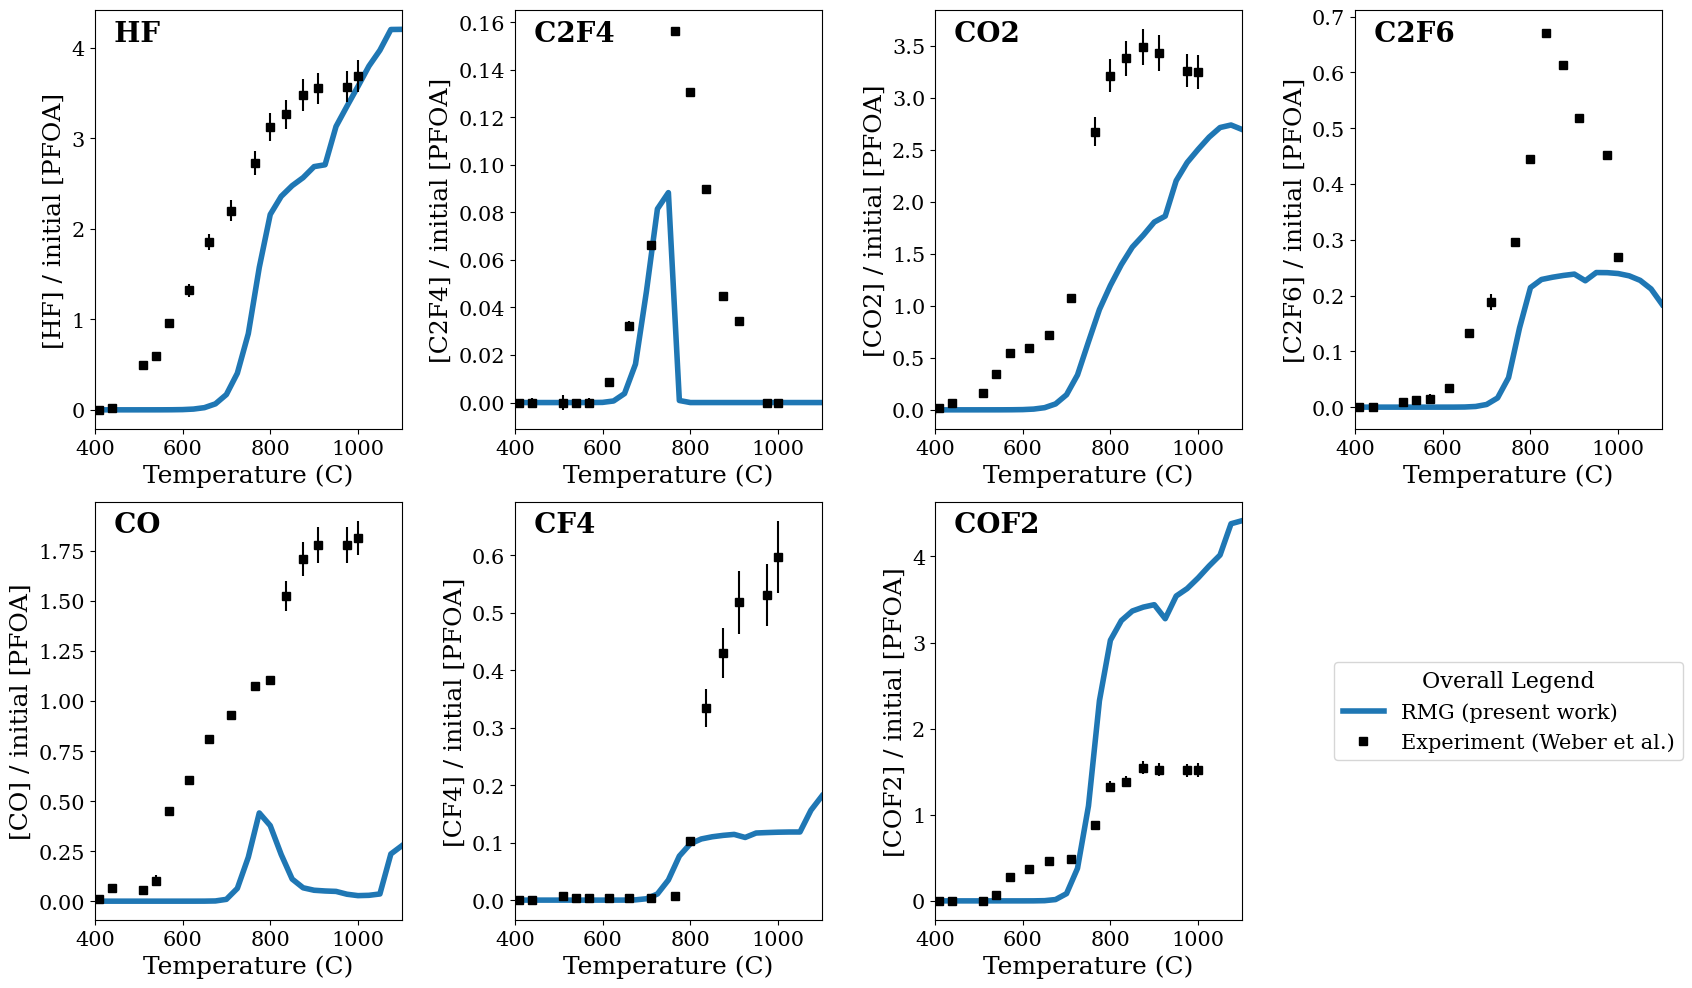

In [9]:
with open('./rmg_skel_AB2_50ml_324corespec.json', 'r') as file:
   rmg_pfas_results_50ml_data = json.load(file)


plot_concentration_ratios_weber = ['HF', 'C2F4', 'CO2', 'C2F6', 'CO', 'CF4', 'COF2'] #species names in Weber model


axes_for_plotting_weber = {'HF': [0,0],
                    'C2F4': [0,1],
                    'CO2': [0,2],
                    'C2F6': [0,3],
                    'CO': [1,0],
                    'CF4': [1,1],
                    'COF2': [1,2]}

plot_concentration_ratios = ['HF(11)', 'C2F4(64)', 'CO2(13)', 'C2F6(51)', 'CO(12)', 'CF4(23)', 'COF2(25)']

axes_for_plotting = {'HF(11)': [0,0],
                    'C2F4(64)': [0,1],
                    'CO2(13)': [0,2],
                    'C2F6(51)': [0,3],
                    'CO(12)': [1,0],
                    'CF4(23)': [1,1],
                    'COF2(25)': [1,2]}

exp_mapping = {'HF(11)': 'HF', 
'C2F4(64)':'C2F4', 
'CO2(13)':'CO2', 
'C2F6(51)':'C2F6', 
'CO(12)':'CO', 
'CF4(23)': 'CF4', 
'COF2(25)':'COF2'}

fig, axs = plt.subplots(2, 4, figsize=(17, 10))
chemkins_to_convert=['317_edited']
chemkins_to_convert=[317, '317_edited']

lw = 4

error_bar_data = get_errors_50mlpermin()

for RMG_spc, web_spc in zip(plot_concentration_ratios, plot_concentration_ratios_weber): 
    
    print(RMG_spc)

    #get plotting axis
    plotting_axis = axes_for_plotting[RMG_spc]


    #RMG PFAS
    exit_concentrations,  temps_to_plot = rmg_pfas_results_50ml_data[RMG_spc]
    axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations, '-', linewidth = lw, color='tab:blue', label="RMG (present work)")


    #RMG main
    # exit_concentrations,  temps_to_plot = rmg_main_results_300spec_data[RMG_spc]
    # # axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations, '-.', linewidth=lw, color='tab:blue', label="RMG (main)")

   
    # #RMG main
    # exit_concentrations,  temps_to_plot = rmg_main_results_435spec_data[RMG_spc]
    # axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations, '--', linewidth=lw, color='tab:blue', label="RMG (main)")

   



    #Weber mech using our simulation
    # (exit_concentrations_weber, temps_to_plot) = weber_results_data[web_spc]
    # axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations_weber, ':', color='r', linewidth = lw, label = 'Weber et al.')

    


    #error bars

    

    
    # axs[plotting_axis[0], plotting_axis[1]].plot(exp_data['experiments'][0], exp_data['experiments'][1], 's', c='black', label='Weber exp (data digitilizer)')

    #also grab the Weber experiment data that I directly received via emailed excel sheet, just to be safe
    exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet = get_raw_data_50mLmin(exp_mapping[RMG_spc])
    # for temp, conc_ratio in zip(exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet):
        # axs[plotting_axis[0], plotting_axis[1]].errorbar(temp, conc_ratio, yerr = yerr, fmt='none', c='black')
    for temp, conc_ratio_pt, yerror_lowerbound, yerror_lowerbound_temp in zip(exp_temps_from_excel_sheet[1:], exp_conc_ratios_from_excel_sheet[1:], error_bar_data[web_spc][0], error_bar_data[web_spc][1]):
        yerr = conc_ratio_pt - yerror_lowerbound
        # print(temp, yerror_lowerbound_temp )
        axs[plotting_axis[0], plotting_axis[1]].errorbar(temp, conc_ratio_pt, yerr = abs(yerr), fmt='none', c='black')
        
    
    axs[plotting_axis[0], plotting_axis[1]].plot(exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet, 's', c='black', label='Experiment (Weber et al.)')
   
        # axs[plotting_axis[0], plotting_axis[1]].errorbar(exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet, yerr = yerrs, fmt='none', c='black')
        # axs[plotting_axis[0], plotting_axis[1]].plot(exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet, 's', c='black', label = 'Weber (excel sheet)') 
   


    axs[plotting_axis[0], plotting_axis[1]].set_xlabel('Temperature (C)')
    axs[plotting_axis[0], plotting_axis[1]].set_ylabel(f'[{web_spc}] / initial [PFOA]')
    axs[plotting_axis[0], plotting_axis[1]].set_title(f'  {web_spc}', fontsize = 20, fontweight='bold', loc='left', y=1.0, pad=-22)
    axs[plotting_axis[0], plotting_axis[1]].set_xlim(400, 1100)
    # axs[plotting_axis[0], plotting_axis[1]].set_ylim(0, 4.5)


#custom legend that will sit in empty plot
h, l = axs[plotting_axis[0], plotting_axis[1]].get_legend_handles_labels()


# target the empty subplot (bottom-right)
ax_legend = axs[1, 3]

# hide its axes and frame
ax_legend.axis('off')
ax_legend.set_frame_on(False)

# place the combined legend in this specific subplot
ax_legend.legend(h, l, loc='center', title="Overall Legend", fontsize=15, title_fontsize=16)

# plt.legend()
plt.show()
fig.savefig('./model_results_rmgpfas_50mlmin.pdf')

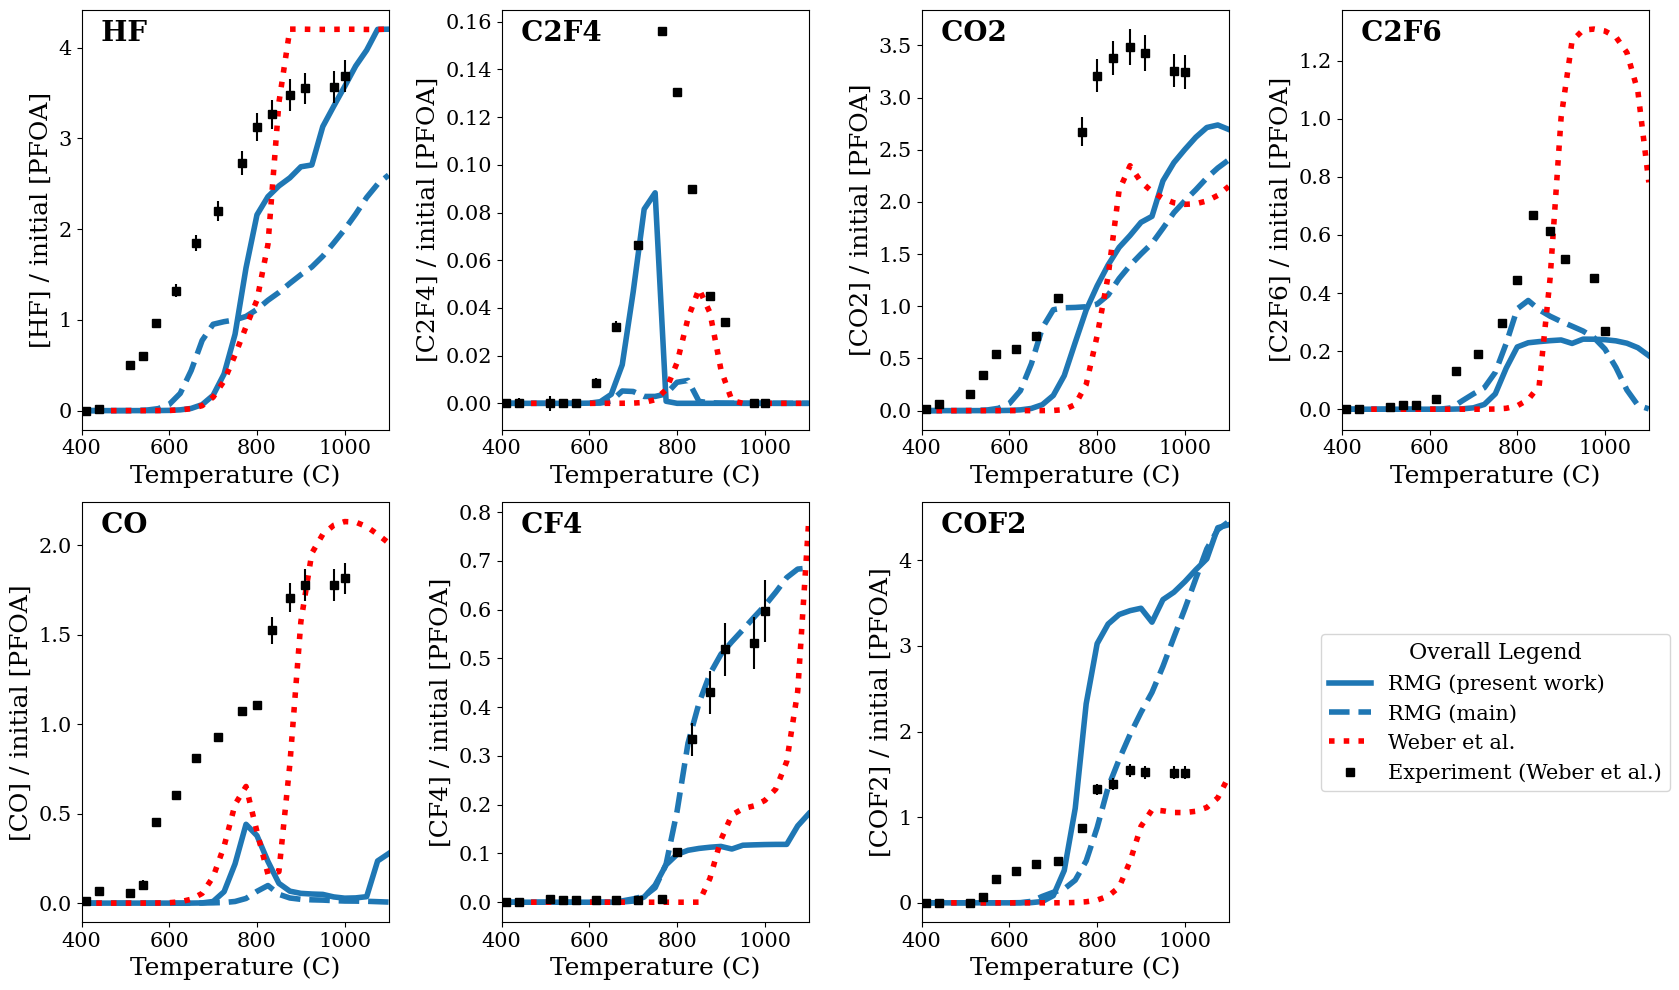

In [14]:
with open('./rmg_skel_AB2_50ml_324corespec.json', 'r') as file:
   rmg_pfas_results_50ml_data = json.load(file)


with open('./weber_results_50ml.json', 'r') as file:
   weber_results_50ml_data = json.load(file)

with open('./rmg_main_results_50ml.json', 'r') as file:
   rmg_main_results_50ml_data = json.load(file)

plot_concentration_ratios_weber = ['HF', 'C2F4', 'CO2', 'C2F6', 'CO', 'CF4', 'COF2'] #species names in Weber model


axes_for_plotting_weber = {'HF': [0,0],
                    'C2F4': [0,1],
                    'CO2': [0,2],
                    'C2F6': [0,3],
                    'CO': [1,0],
                    'CF4': [1,1],
                    'COF2': [1,2]}

plot_concentration_ratios = ['HF(11)', 'C2F4(64)', 'CO2(13)', 'C2F6(51)', 'CO(12)', 'CF4(23)', 'COF2(25)']

axes_for_plotting = {'HF(11)': [0,0],
                    'C2F4(64)': [0,1],
                    'CO2(13)': [0,2],
                    'C2F6(51)': [0,3],
                    'CO(12)': [1,0],
                    'CF4(23)': [1,1],
                    'COF2(25)': [1,2]}

exp_mapping = {'HF(11)': 'HF', 
'C2F4(64)':'C2F4', 
'CO2(13)':'CO2', 
'C2F6(51)':'C2F6', 
'CO(12)':'CO', 
'CF4(23)': 'CF4', 
'COF2(25)':'COF2'}

fig, axs = plt.subplots(2, 4, figsize=(17, 10))
chemkins_to_convert=['317_edited']
chemkins_to_convert=[317, '317_edited']

lw = 4

for RMG_spc, web_spc in zip(plot_concentration_ratios, plot_concentration_ratios_weber): 
    
    # print(RMG_spc)

    #get plotting axis
    plotting_axis = axes_for_plotting[RMG_spc]


    #RMG PFAS
    exit_concentrations,  temps_to_plot = rmg_pfas_results_50ml_data[RMG_spc]
    axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations, '-', linewidth = lw, color='tab:blue', label="RMG (present work)")


    #RMG main
    # exit_concentrations,  temps_to_plot = rmg_main_results_300spec_data[RMG_spc]
    # axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations, '-.', linewidth=lw, color='tab:blue', label="RMG (main)")

   
    # #RMG main
    exit_concentrations,  temps_to_plot = rmg_main_results_50ml_data[RMG_spc]
    axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations, '--', linewidth=lw, color='tab:blue', label="RMG (main)")

   



    #Weber mech using our simulation
    (exit_concentrations_weber, temps_to_plot) = weber_results_50ml_data[web_spc] #these keys are actually RMG names. made a mistake
    axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations_weber, ':', color='r', linewidth = lw, label = 'Weber et al.')

    
    #grab Weber experiment data that I pulled from his published plots via data digitilizer
    exp_data = get_experiment_data(exp_mapping[RMG_spc])

    #error bars
    #make sure their ordered 
    exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet = get_raw_data_50mLmin(exp_mapping[RMG_spc])
    # for temp, conc_ratio in zip(exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet):
        # axs[plotting_axis[0], plotting_axis[1]].errorbar(temp, conc_ratio, yerr = yerr, fmt='none', c='black')
    for temp, conc_ratio_pt, yerror_lowerbound, yerror_lowerbound_temp in zip(exp_temps_from_excel_sheet[1:], exp_conc_ratios_from_excel_sheet[1:], error_bar_data[web_spc][0], error_bar_data[web_spc][1]):
        yerr = conc_ratio_pt - yerror_lowerbound
        # print(temp, yerror_lowerbound_temp )
        axs[plotting_axis[0], plotting_axis[1]].errorbar(temp, conc_ratio_pt, yerr = abs(yerr), fmt='none', c='black')
        
    #also grab the Weber experiment data that I directly received via emailed excel sheet, just to be safe
    exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet = get_raw_data_50mLmin(exp_mapping[RMG_spc])
    # for temp, conc_ratio in zip(exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet):
        # axs[plotting_axis[0], plotting_axis[1]].errorbar(temp, conc_ratio, yerr = yerr, fmt='none', c='black')
    axs[plotting_axis[0], plotting_axis[1]].plot(exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet, 's', c='black', label='Experiment (Weber et al.)')
   
        # axs[plotting_axis[0], plotting_axis[1]].errorbar(exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet, yerr = yerrs, fmt='none', c='black')
        # axs[plotting_axis[0], plotting_axis[1]].plot(exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet, 's', c='black', label = 'Weber (excel sheet)') 
   


    axs[plotting_axis[0], plotting_axis[1]].set_xlabel('Temperature (C)')
    axs[plotting_axis[0], plotting_axis[1]].set_ylabel(f'[{web_spc}] / initial [PFOA]')
    axs[plotting_axis[0], plotting_axis[1]].set_title(f'  {web_spc}', fontsize = 20, fontweight='bold', loc='left', y=1.0, pad=-22)
    axs[plotting_axis[0], plotting_axis[1]].set_xlim(400, 1100)
    # axs[plotting_axis[0], plotting_axis[1]].set_ylim(0, 2)


#custom legend that will sit in empty plot
h, l = axs[plotting_axis[0], plotting_axis[1]].get_legend_handles_labels()


# target the empty subplot (bottom-right)
ax_legend = axs[1, 3]

# hide its axes and frame
ax_legend.axis('off')
ax_legend.set_frame_on(False)

# place the combined legend in this specific subplot
ax_legend.legend(h, l, loc='center', title="Overall Legend", fontsize=15, title_fontsize=16)

# plt.legend()
plt.show()
fig.savefig('./model_results_three_50mlmin.pdf')